# San Francisco's soft-story retrofits, parcel by parcel

A soft-story building has a weak ground floor (garages or shopfronts under flats) that can fold in an earthquake. San
Francisco's Mandatory Soft Story Retrofit Program (2013) required owners of about 5,000 wood-frame buildings of three
or more storeys and five or more units to strengthen them, in four tiers with deadlines from 2017 to 2020.

The city publishes the program's list (tier and status, today) and every building permit, but not when each building
was finished, and not which buildings stand on ground that can liquefy. Here each parcel's completion date comes from
its soft story permits, and its ground from the state's mapped liquefaction zones. The shapes in `data/geometry/` were
made in [Plotlay](https://www.getplotlay.com). This notebook reads only `../data`.

In [1]:
import pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
DATA = '../data'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
p = pd.read_csv(f'{DATA}/tables/parcels.csv', dtype={'blklot': str, 'tier': str})
print(len(p), 'parcels on the list'); print(p.status.value_counts().to_string())

4901 parcels on the list
status
Complete         4662
Non-compliant     227
Newly added        12


## 1. Done today, in and out of liquefaction zones

In [2]:
g = p.groupby('liquefaction').agg(parcels=('blklot', 'size'), complete=('status', lambda s: (s == 'Complete').sum()), non_compliant=('status', lambda s: (s == 'Non-compliant').sum()))
g['share_complete'] = (g.complete / g.parcels).round(4)
g

,parcels,complete,non_compliant,share_complete
liquefaction,,,,
no,4201,4003,190,0.9529
unknown,2,2,0,1.0000
yes,698,657,37,0.9413


## 2. Year by year

A parcel is done in a year once a soft story permit on it was completed by the end of that year. Parcels the program
lists as complete with no completed permit found (the `complete_no_year` ones) are never counted as done here, so the
curves end below the status figures above.

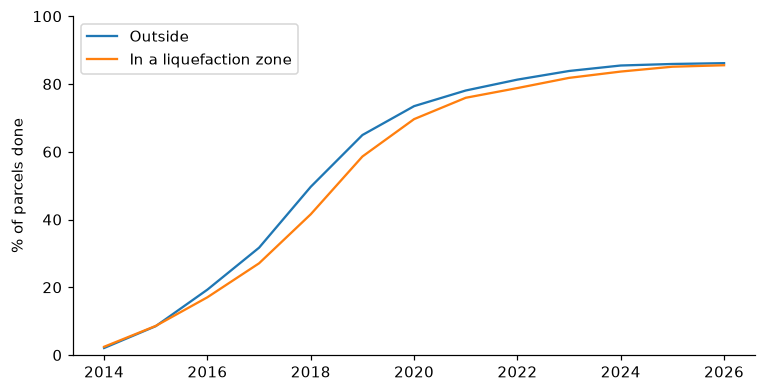

,Outside,In a liquefaction zone
2014,2.1,2.4
2015,8.5,8.6
2016,19.3,17.0
2017,31.7,27.1
2018,49.7,41.5
2019,64.9,58.6
2020,73.5,69.6
2021,78.1,75.9
2022,81.3,78.8
2023,83.8,81.8


In [3]:
pp = p[p.liquefaction != 'unknown'].copy()
years = range(2014, 2027)
cur = pd.DataFrame({grp: [((df.year_done <= y) & df.year_done.notna()).mean() * 100 for y in years] for grp, df in pp.groupby('liquefaction')}, index=years)
cur.columns = ['Outside' if c == 'no' else 'In a liquefaction zone' for c in cur.columns]
ax = cur.plot(figsize=(8, 4), ylabel='% of parcels done'); ax.set_ylim(0, 100); plt.show()
cur.round(1)

## 3. Why the zones lagged: the tiers

The ordinance put buildings in mapped liquefaction zones in Tier IV, the last deadline (15 September 2020), unless they
were Tier I. Most zone parcels are Tier IV, so they finished later by design.

In [4]:
DEADLINE = {'1': '2017-09-15', '2': '2018-09-15', '3': '2019-09-15', '4': '2020-09-15'}
p['completed'] = pd.to_datetime(p.completed, errors='coerce')
rows = []
for t, d in DEADLINE.items():
    df = p[p.tier == t]
    rows.append({'tier': t, 'deadline': d, 'parcels': len(df), 'in_liquefaction_zone': int((df.liquefaction == 'yes').sum()),
                 'done_by_deadline_pct': round(100 * (df.completed <= pd.Timestamp(d)).mean(), 1), 'complete_now_pct': round(100 * (df.status == 'Complete').mean(), 1)})
pd.DataFrame(rows)

,tier,deadline,parcels,in_liquefaction_zone,done_by_deadline_pct,complete_now_pct
0,1,2017-09-15,8,1,37.5,87.5
1,2,2018-09-15,506,44,62.6,96.6
2,3,2019-09-15,3373,248,62.6,95.8
3,4,2020-09-15,1014,405,57.8,92.3


## 4. On the map

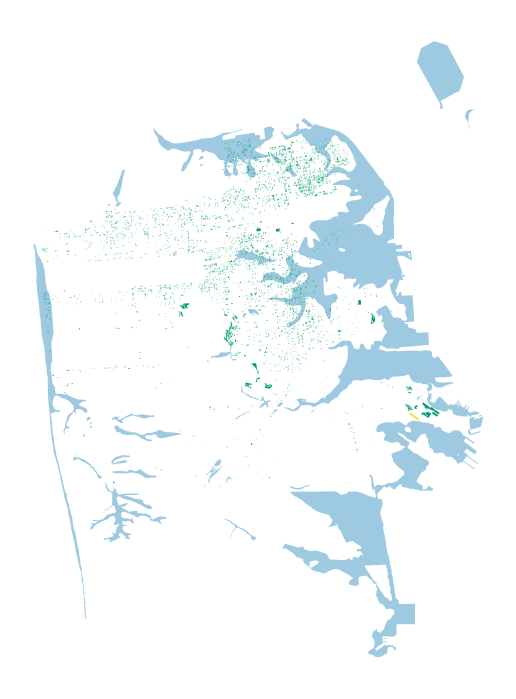

4899 parcel shapes; 43 zone pieces


In [5]:
sh = gpd.read_file(f'{DATA}/geometry/soft_story_parcels.geojson'); z = gpd.read_file(f'{DATA}/geometry/liquefaction_zones.geojson')
sh = sh.merge(p[['blklot', 'status']], left_on='key', right_on='blklot', how='left')
ax = z.to_crs(32610).plot(color='#9ecae1', figsize=(8, 8))
col = {'Complete': '#009E73', 'Non-compliant': '#F0E442', 'Newly added': '#0072B2'}  # as in the app
for s, c in col.items(): sh[sh.status == s].to_crs(32610).plot(ax=ax, color=c, markersize=2, label=s)
ax.set_axis_off(); plt.show()
print(len(sh), 'parcel shapes;', len(z), 'zone pieces')

## Read it carefully

- **Completion dates come from permits.** The earliest completed soft story permit on the parcel; a revision or a
  later voluntary permit is ignored. The program's own status is the authority on whether a building complies.
- **The zones are today's.** The California Geological Survey revised part of San Francisco's map in 2021; the
  program assigned tiers from the maps of its time, so a few zone parcels sit in Tiers II and III.
- **A parcel is in a zone when a point inside it is.** `liq_share` in `parcels.csv` gives the share of its area.